Saving Screenshot 2026-07-25 233501.png to Screenshot 2026-07-25 233501.png


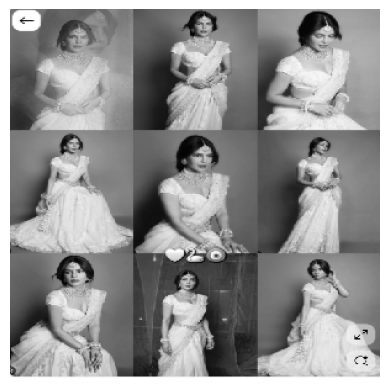

In [2]:
import tensorflow as tf

import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

name = list(uploaded.keys())[0]

image = tf.keras.utils.load_img(name, color_mode = "grayscale", target_size = (300,300))

image = tf.keras.utils.img_to_array(image)/255.0

plt.imshow(image[:,:,0],cmap = "gray")

plt.axis("off")

plt.show()

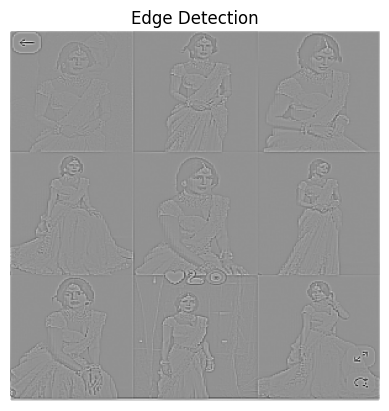

In [3]:
image = tf.expand_dims(image, axis=0)

kernel = tf.constant([

    [-1, -1, -1],

    [-1,  8, -1],

    [-1, -1, -1]

], dtype=tf.float32)

kernel = tf.reshape(kernel, (3, 3, 1, 1))

edges = tf.nn.conv2d(
    image,
    filters=kernel,
    strides=1,
    padding="SAME"
)
plt.imshow(tf.squeeze(edges), cmap="gray")
plt.title("Edge Detection")
plt.axis("off")
plt.show()

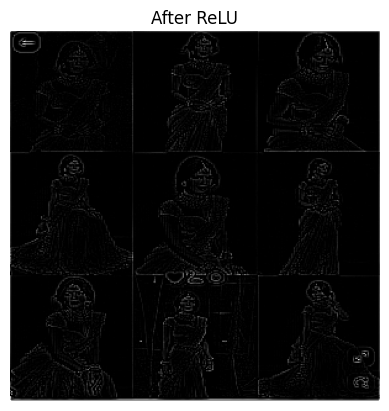

In [4]:
relu = tf.nn.relu(edges)

plt.imshow(tf.squeeze(relu), cmap="gray")

plt.title("After ReLU")

plt.axis("off")

plt.show()

In [5]:
pooled = tf.nn.max_pool2d(

    relu,

    ksize=2,

    strides=2,

    padding="SAME"

)

print("Before Pooling:", relu.shape)

print("After Pooling:", pooled.shape)






Before Pooling: (1, 300, 300, 1)
After Pooling: (1, 150, 150, 1)


In [6]:
flatten = tf.keras.layers.Flatten()

flattened = flatten(pooled)

print(flattened.shape)

print(pooled.shape)

(1, 22500)
(1, 150, 150, 1)


In [7]:
dense = tf.keras.layers.Dense(3,activation = "softmax")

output = dense(flattened)

print("Dense Outputshape:",output.shape)

print("Output:",output.numpy())

Dense Outputshape: (1, 3)
Output: [[0.40896523 0.46939316 0.12164155]]


In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [8]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


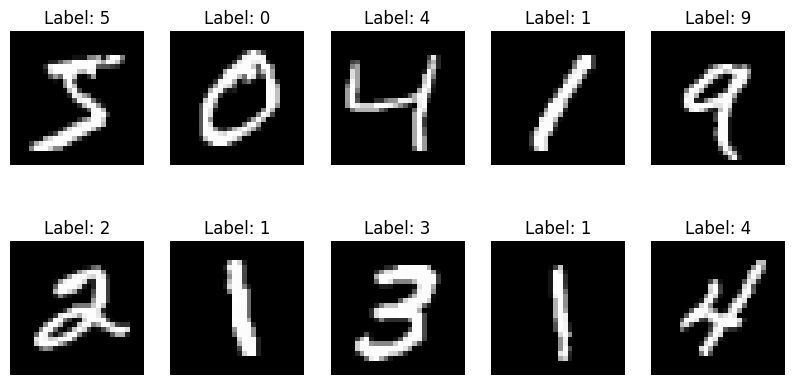

In [9]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.show()

In [10]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

In [11]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - accuracy: 0.9223 - loss: 0.2605 - val_accuracy: 0.9837 - val_loss: 0.0585
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 105ms/step - accuracy: 0.9771 - loss: 0.0758 - val_accuracy: 0.9895 - val_loss: 0.0387
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 81s 102ms/step - accuracy: 0.9842 - loss: 0.0520 - val_accuracy: 0.9885 - val_loss: 0.0399
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 105ms/step - accuracy: 0.9880 - loss: 0.0417 - val_accuracy: 0.9895 - val_loss: 0.0389
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 84s 109ms/step - accuracy: 0.9892 - loss: 0.0355 - val_accuracy: 0.9900 - val_loss: 0.0345


In [13]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9909 - loss: 0.0290
Test Accuracy: 0.9908999800682068
Test Loss: 0.029011771082878113


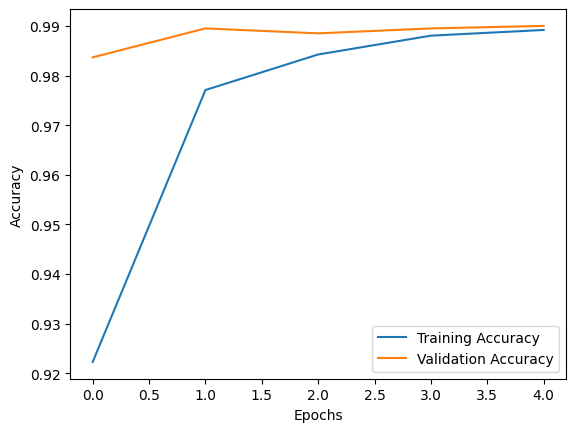

In [14]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

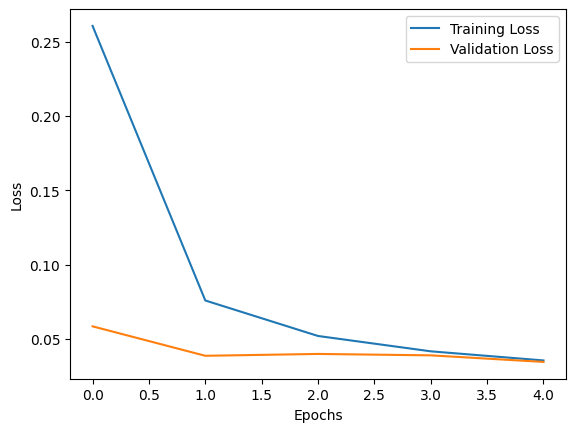

In [15]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()